# Exercices 5

[Télécharger l'exercice](../05_exercice.zip)

# Exercise : Intrusion magmatique 

Le but de cet exercice est de modéliser deux intrusions magmatiques successives qui réchauffent la roche environnante en résolvant un problème de diffusion. Ce problème peut être simplifié en une dimension (1D) où la dimension $x$ représente la distance orthogonale aux intrusions.
 
![](./fig/dykes.png)

*Figure 1: Représentation des deux intrusions successives et la diffusion de leur chaleur dans la roche environnante.*

Les deux intrusions s'infiltrent l'une après l'autre à une profondeur d'environ 1 km, où la roche encaissante a une température de 30°C. La température initiale des intrusions est de 1000°C, et le magma commence à refroidir dès son arrivée à cet emplacement. La seconde intrusion s'infiltre 15 ans plus tard, à 30 m à droite de la première (mesurée entre leurs centres). La première intrusion a une épaisseur de 24 m, tandis que la seconde mesure 10 m d'épaisseur. La simulation débute immédiatement après la formation de la première intrusion. Aux deux extrémités (gauche et droite) de l'espace à modéliser, la roche est fracturée et traverse un flux d'eau important, maintenant ainsi une température constante de 30°C.

Pour résoudre ce problème, il faut discrétiser et implémenter les mêmes équations de diffusion thermique :

$$ q = -D \frac{\partial T}{dx}, \qquad (1) $$
$$ \frac{\partial T}{\partial t} = -\frac{\partial q}{\partial x}. \qquad (2) $$

Les paramètres physiques sont donnés dans la table suivante :

**Table: paramètres du modèle**

| **Paramètres**                | **Valeurs**         |
|-------------------------------|---------------------|
| Température ambiante          | 30°C                |
| Température de l'intrusion    | 1000°C              |
| Température limite gauche     | 30°C                |
| Température limite droite     | 30°C                |
| Centre de l'intrusion 1       | 80 m                |
| Centre de l'intrusion 2       | 110 m               |
| Épaisseur de l'intrusion 1    | 24 m                |
| Épaisseur de l'intrusion 2    | 10 m                |
| Intrusion de l'intrusion 2    | 15 ans              |
| Diffusivité de la roche       | 50 m²/yr            |
| Longueur du modèle            | 200 m               |

Écrire un code afin de répondre aux questions suivantes. Il s'agit d'écrire un code unique, avec un paramètre `Q` défini à `1` ou `2` pour traiter les questions 1 et 2.

**Q1 :** Après combien de temps une sonde positionnée 80 m à droite du centre de la première intrusion enregistrera une température de 100°C ? Stoppez votre code quand cette condition est remplie. 

**Q2 :** Changez les deux conditions de bords en supposant un flux nul de chaleur et refaites l'expérience. Analysez l'influence des conditions de bords sur le temps de passage de la sonde au-delà de 100°C.

### ✅ **À vous de faire !** 

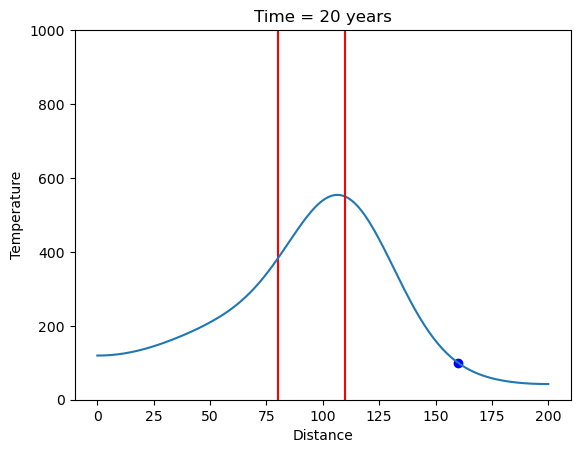

La température de la sonde a atteint 100°C après 20.02 années


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display

# Version du code à effectuer (1: température fixe au bords; 2: flux nul au bords)
Q = 2

# Physical parameters
D = 50                      # diffusivité de la roche, en m2/an
Lx = 200                    # longueur du modèle, en m
ttot = 1000                 # temps total, en années (exprès gros vu qu'il y a un break)
T_ambiante = 30             # température ambiante en degrés
T_intrusion = 1000          # température de l'intrusion en degrés
T_lim_g = 30                # température à la limite gauche du modèle, en degrés
T_lim_d = 30                # température à la limite droite du modèle, en degrés
x_int1 = 80                 # position de la première intrusion, en m
x_int2 = 110                # position de la deuxième intrusion, en m
width_int1 = 24             # largeur intrusion 1
width_int2 = 10             # largeur intrusion 1
t_int2 = 15                 # moment de la deuxième intrusion, en années
T_thr = 100                 # température à ne pas dépasser à la x_sonde (break)

x_sonde = x_int1 + 80       # sonde positionnée à 80m à droite de la première intrusion

# Numerical parameters
nx = 201                    # nombre de cellules
dx = Lx / (nx-1)            # taille d'une cellule
x = np.linspace(0, Lx, nx)  # coordonnées des points de maillage
dt = dx**2 / (2.1 * D)      # pas de temps (imposé)
nt = int(ttot/dt)           # nombre de pas de temps
nout = 50                   # afficher la figure tous les X time step

# Conditions initiales
T = np.ones(nx) * T_ambiante        # température sur toute la largeur du modèle
T[int((x_int1-(width_int1/2))/dx):int((x_int1+(width_int1/2))/dx)] = T_intrusion # température initiale pour la première intrusion
q = np.zeros(nx-1)                  # initialisation du flux pour avoir valeur cohérente dans la boucle temporelle
time = 0                            # initialisation du temps

# Conditions de température en marge (condition Q=1)
if Q == 1:
    T[0] = T_lim_g
    T[-1] = T_lim_d

# Conditions de température en marge (condition Q=2)
if Q == 2:
    T[0] = T[1]
    T[-1] = T[-2]

# Création du plot 
fig, ax = plt.subplots()

# Time loop
for it in range(nt):
    time += dt                          # track time
    q = - D * ( T[1:] - T[:-1] ) / dx   # Mettre a jour le flux q en fonction de C 
    dCdt = - ( q[1:] - q[:-1] ) / dx    # Mettre a jour dCdt
    T[1:-1] += dCdt * dt                # Mettre a jour C

    # initialisation de la deuxième intrusion
    if int(time) == t_int2:
        T[int((x_int2-(width_int2/2))/dx):int((x_int2+(width_int2/2))/dx)] = T_intrusion

    # Conditions de température en marge (condition Q=1)
    """Mise à jour à chaque itération car sinon défault pareil que Q=1"""
    if Q == 1:
        T[0] = T_lim_g
        T[-1] = T_lim_d

    # Conditions de température en marge (condition Q=2)
    if Q == 2:
        T[0] = T[1]    # condition de flux nul (pas besoin d'ajouter -dt*a)
        T[-1] = T[-2]  # condition de flux nul (pas besoin d'ajouter -dt*b)

    # Condition de stop (version Q=1 et Q=2, sinon boucle infinie)
    if T[int(x_sonde/dx)] >= T_thr:
        t_depassement = time
        break

    # plot
    if it % nout == 0:
        clear_output(wait=True) 
        ax.cla()
        ax.set_ylim(0, 1000)
        ax.set_title("Time = " + str(int(time)) + " years") # affichage du temps
        ax.plot([x_int1, x_int1], [0, 1000], 'r')           # position intrusion 1
        ax.plot(x_sonde, T_thr, 'bo')                       # position et température max sonde
        ax.plot(x, T)
        ax.set_xlabel('Distance')
        ax.set_ylabel('Temperature')
        if time >= t_int2:
            ax.plot([x_int2, x_int2], [0, 1000], 'r')       # position intrusion 2
        display(fig)
        plt.pause(0.1) 
        

print(f"La température de la sonde a atteint 100°C après {t_depassement:.2f} années")